
# Лабораторная работа 5: Уровень решения проблемы обработки и генерации естественного языка, ч.5

Расширение семантического анализатора **Лабораторной работы 4** (CNN/GRU на
PyTorch) средствами **генерации осмысленного текста только на его основе**.

В работе используются:

* **LSTM-языковая модель**, обусловленная темой анализатора;
* **sequence-to-sequence** — LSTM-энкодер → LSTM-декодер с аддитивным вниманием
  Багданау (задачи «документ → первый абзац» и «предложение → следующее»);
* **шаблонный генератор** (разрешён условием) как baseline;
* **гибридное ранжирование** кандидатов по шести признакам;
* **n-граммные ограничения декодирования** по предложениям корпуса.

Генератор не использует внешние предобученные модели: корпус, темы, словарь и
векторы документов берутся у `lab_4`, LSTM и seq2seq обучаются с нуля на этом же
корпусе.

> Ноутбук воспроизводим: все источники случайности фиксируются `seed=42`,
> обучение идёт на CPU.



## 1. Постановка задачи

Требуется:

1. взять семантический анализатор `lab_4` (`NeuralAnalyzer`, CNN/GRU) как основу;
2. реализовать генерацию текста **только на его корпусе и представлениях**;
3. использовать нейросети классов **LSTM** и методы **sequence-to-sequence**;
4. дополнительно реализовать шаблонный генератор (разрешён условием);
5. показать примеры работы генератора и **четырёх** полученных семантических
   анализаторов (`lab_1`–`lab_4`), в том числе на пользовательских данных;
6. привести сравнительное описание анализаторов и генераторов.

План ноутбука: данные → семантическое ядро → LSTM → seq2seq → шаблоны →
гибрид → четыре анализатора → пользовательский корпус → RuReviews → выводы.



## 2. Окружение и импорт

`matplotlib` используется только для графиков; ядро генерации от него не зависит.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig_lab5")

import glob
import json
import math
import sys
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

_PROJECT = Path.cwd().resolve()
if _PROJECT.name == "notebooks":
    _PROJECT = _PROJECT.parents[1]
if str(_PROJECT) not in sys.path:
    sys.path.insert(0, str(_PROJECT))
assert (_PROJECT / "lab_5").is_dir(), _PROJECT

from lab_5.src import (
    GeneratingAnalyzer,
    SemanticSuite,
    SemanticAnalyzer,
    DocVecAnalyzer,
    NeuralAnalyzer,
    SentimentAnalyzer,
    load_text_files,
    load_corpus,
    doc_tokens,
    sent_tokenize,
)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
print("torch:", torch.__version__)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")
print("project:", _PROJECT)


torch: 2.8.0+cpu
device: cpu
project: /data/Projects/NLP



## 3. Данные

* **Демо-корпус** `lab_2/data/sample_docs/` — 42 документа по 6 темам
  (finance, food, health, sport, tech, travel);
* **Пользовательский корпус** `lab_2/data/custom_corpus/` — 20 документов по
  4 темам (auto, edu, fashion, music);
* **RuReviews** `lab_1/data/rureviews.csv` — отзывы с тональностью.

Для обучения нужны минимум две темы: явные `labels` или имена файлов
`<тема>_<номер>.txt`.


In [2]:

demo_paths = sorted(glob.glob(str(_PROJECT / "lab_2/data/sample_docs/*.txt")))
custom_paths = sorted(glob.glob(str(_PROJECT / "lab_2/data/custom_corpus/*.txt")))
demo_texts = load_text_files(demo_paths)
custom_texts = load_text_files(custom_paths)
demo_sources = [Path(p).name for p in demo_paths]
custom_sources = [Path(p).name for p in custom_paths]

print("демо:", len(demo_texts), "документов,", len(set(s.split("_")[0] for s in demo_sources)), "тем")
print("пользовательский:", len(custom_texts), "документов,", len(set(s.split("_")[0] for s in custom_sources)), "тем")
print("\nПример демо-документа:")
print(demo_texts[0])


демо: 42 документов, 6 тем
пользовательский: 20 документов, 4 тем

Пример демо-документа:
Банк предложил клиентам вклад с повышенной ставкой на первый год.
Проценты начисляются ежемесячно, а снять деньги без потери дохода нельзя.
Экономисты считают, что такой вклад выгоден при высокой инфляции.



## 4. Семантическое ядро `lab_4`

Загружаем готовые CNN/GRU-анализаторы и проверяем, что они дают темы, поиск и
векторы документов. Именно эти представления будет использовать генератор.


In [3]:

cnn = NeuralAnalyzer(str(_PROJECT / "lab_4/src/models/cnn_demo"), method="cnn")
rnn = NeuralAnalyzer(str(_PROJECT / "lab_4/src/models/rnn_demo"), method="rnn")
print("CNN:", cnn.n_docs, "документов, dim =", cnn.dim)
print("GRU:", rnn.n_docs, "документов, dim =", rnn.dim)

for query in [
    "Футбольный матч и тренировка команды на стадионе",
    "Новый ноутбук с мощным процессором и большим экраном",
]:
    print("\nзапрос:", query)
    print("  CNN:", [(m.source, round(m.score, 3)) for m in cnn.query(query, top_n=2)])
    print("  GRU:", [(m.source, round(m.score, 3)) for m in rnn.query(query, top_n=2)])

print("\nклассификация темы:")
print("  CNN:", cnn.predict("Футбольный матч и тренировка команды").label)
print("  GRU:", rnn.predict("Футбольный матч и тренировка команды").label)
print("  вектор демо-документа:", cnn.doc_vector(0).shape)


CNN: 42 документов, dim = 192
GRU: 42 документов, dim = 128

запрос: Футбольный матч и тренировка команды на стадионе
  CNN: [('sport_07.txt', 0.847), ('sport_06.txt', 0.838)]
  GRU: [('sport_01.txt', 0.843), ('sport_05.txt', 0.79)]

запрос: Новый ноутбук с мощным процессором и большим экраном
  CNN: [('tech_01.txt', 0.81), ('tech_05.txt', 0.769)]
  GRU: [('tech_02.txt', 0.561), ('tech_01.txt', 0.559)]

классификация темы:
  CNN: sport
  GRU: sport
  вектор демо-документа: (192,)



## 5. LSTM-языковая модель

Модель учится на **отдельных предложениях** корпуса. На каждом шаге к эмбеддингу
слова конкатенируется эмбеддинг темы, поэтому генерация обусловлена темой
анализатора. Словарь — словоформы (`doc_tokens(..., "raw")`), чтобы текст был
читаемым; анализатор при этом продолжает работать с каноническими леммами.

Обучаем демо-модель заново (40 эпох семантического ядра, 80 эпох LSTM и
seq2seq). Это занимает около минуты на CPU.


In [4]:

generator = GeneratingAnalyzer(
    str(_PROJECT / "lab_5/src/models/gen_cnn_demo"), semantic_method="cnn"
)
t0 = time.time()
demo_stats = generator.fit(
    demo_texts, sources=demo_sources,
    semantic_epochs=40, semantic_batch_size=8, semantic_max_len=48,
    semantic_embedding_dim=64, semantic_hidden_dim=64, semantic_num_filters=64,
    embedding_dim=64, hidden_dim=96, num_layers=2, dropout=0.1, topic_dim=16,
    max_len=24, seq2seq_hidden_dim=64, seq2seq_num_layers=1,
    epochs=80, seq2seq_epochs=80, batch_size=8,
    max_src_len=48, max_tgt_len=24, seed=SEED,
)
print("обучение:", round(time.time() - t0, 1), "c")
for key in ("n_docs", "n_features", "n_classes", "dim", "semantic_accuracy",
            "lm_loss", "lm_perplexity", "lm_token_accuracy",
            "lead_pairs", "next_pairs", "lead_loss", "next_loss"):
    value = demo_stats[key]
    if isinstance(value, float):
        value = round(value, 4)
    print(f"  {key:20s} {value}")


обучение: 49.7 c
  n_docs               42
  n_features           923
  n_classes            6
  dim                  192
  semantic_accuracy    1.0
  lm_loss              0.8587
  lm_perplexity        2.3602
  lm_token_accuracy    0.903
  lead_pairs           42
  next_pairs           84
  lead_loss            1.3031
  next_loss            0.8483


In [5]:

metrics = generator.metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metrics["lm_history"], color="tab:blue")
axes[0].set_title("LSTM-языковая модель: потеря по эпохам")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("cross-entropy")
axes[0].grid(alpha=0.3)
axes[1].plot(metrics["lead_history"], label="lead: документ → первый абзац")
axes[1].plot(metrics["next_history"], label="next: предложение → следующее")
axes[1].set_title("sequence-to-sequence: потеря по эпохам")
axes[1].set_xlabel("эпоха")
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
plot_path = _PROJECT / "lab_5/data/lab_5_training.png"
plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_path, dpi=150)
plt.close(fig)
print("сохранено:", plot_path)


сохранено: /data/Projects/NLP/lab_5/data/lab_5_training.png



### Генерация всеми режимами

`template` — шаблонный baseline, `lstm` — продолжение LSTM, `seq2seq` —
следующее предложение, `hybrid` — лучший кандидат по шести признакам.


In [6]:

queries = [
    ("футбольный матч и тренировка команды", "sport"),
    ("новый ноутбук с мощным процессором", "tech"),
    ("как приготовить вкусный суп из овощей", "food"),
    ("пациент жалуется на боль и слабость", "health"),
    ("туристы забронировали номер и купили билеты", "travel"),
    ("он вложил сбережения чтобы получить прибыль", "finance"),
]
for prompt, topic in queries:
    print("\n===", prompt, "| тема:", topic)
    for method in ("template", "lstm", "seq2seq", "hybrid"):
        result = generator.generate(
            prompt, topic=topic, method=method, max_words=20,
            temperature=0.7, top_k=20, min_words=6, seed=7,
        )
        print(f"  {method:9s} [{result.score:.3f}] {result.text}")



=== футбольный матч и тренировка команды | тема: sport


  template  [0.756] В корпусе тема «sport» описывается словами матч, команда и болельщик. Футбольный матч собрал полный стадион, и болельщики поддерживали свою команду с первой минуты.
  lstm      [0.630] Помогает футболистам справляться с волнением перед важным.


  seq2seq   [0.757] Тренер разбил команду на группы и предложил отрабатывать.


  hybrid    [0.757] Тренер разбил команду на группы и предложил отрабатывать.

=== новый ноутбук с мощным процессором | тема: tech


  template  [0.797] Тема «tech» раскрывается через понятия ноутбук, новый и программа. Новый ноутбук получил быстрый процессор и экран с высокой яркостью.
  lstm      [0.690] Процессор и экран с высокой яркостью.


  seq2seq   [0.685] Что новый интерфейс стал проще а настройки.


... (5 outputs left out)

  lstm      [0.648] И жильё в сезон дорожают вдвое.
  seq2seq   [0.624] Туристы сделали много фотографий и потом.


  hybrid    [0.771] В корпусе тема «travel» описывается словами заранее, отель и опытный. Опытные туристы советуют заранее узнать правила въезда и забронировать отель с бесплатной отменой.

=== он вложил сбережения чтобы получить прибыль | тема: finance
  template  [0.734] Тема «finance» раскрывается через понятия деньга, доход и цена. Доходность на рынке меняется каждый день, и предсказать её точно невозможно.


  lstm      [0.626] Оказалась скромной зато вклад удалось сохранить.
  seq2seq   [0.701] Банк учитывает доход заёмщика и проверяет.


  hybrid    [0.734] Тема «finance» раскрывается через понятия деньга, доход и цена. Доходность на рынке меняется каждый день, и предсказать её точно невозможно.



### Влияние n-граммных ограничений

Без ограничений LSTM свободно выбирает любое слово словаря и на малом корпусе
быстро «уплывает». С ограничениями следующий токен выбирается только из
переходов, встречавшихся в предложениях корпуса (триграмма → биграмма). Сравним.


In [7]:

prompt, topic = "новый ноутбук с мощным процессором", "tech"
for constrain in (True, False):
    for temperature in (0.0, 0.7, 1.0):
        result = generator.generate(
            prompt, topic=topic, method="lstm", max_words=16,
            temperature=temperature, top_k=20, min_words=6,
            constrain=constrain, seed=5,
        )
        print(f"constrain={constrain!s:5s} T={temperature:.1f} -> {result.text}")


constrain=True  T=0.0 -> Процессор и экран с высокой яркостью.


constrain=True  T=0.7 -> Процессор и экран с высокой яркостью.


constrain=True  T=1.0 -> Проще а настройки понятнее для новичков.
constrain=False T=0.0 -> Процессор и экран с данные на яркостью.
constrain=False T=0.7 -> Процессор а данные с высокой сложнее.


constrain=False T=1.0 -> Экран процессор и устройство данные и высокой яркостью.



### Реферирование и продолжение

`summarize` использует seq2seq-модель `lead`, `continue_text` — LSTM-модель.


In [8]:
print("seq2seq-реферирование (lead):")
for name in ("sport_01", "tech_01", "food_02", "health_03", "travel_02", "finance_02"):
    text = (_PROJECT / f"lab_2/data/sample_docs/{name}.txt").read_text(encoding="utf-8")
    print(f"  {name:10s} -> {generator.summarize(text, max_words=28, min_words=10)}")

print("\nLSTM-продолжение (continue_text):")
for prompt in ("новый ноутбук получил", "футбольный матч собрал", "врач осмотрел"):
    print(f"  {prompt:24s} -> {generator.continue_text(prompt, max_words=14, temperature=0.7, min_words=6, seed=3)}")


seq2seq-реферирование (lead):


  sport_01   -> Футбольный матч собрал полный стадион и болельщики поддерживали свою команду с первой минуты.
  tech_01    -> Новый ноутбук получил быстрый процессор и экран с высокой яркостью.
  food_02    -> Тесто для пирога замешивают на кефире поэтому основа получается мягкой.


  health_03  -> В больнице открылось новое отделение где пациент может пройти обследование за один.


  travel_02  -> Отель находился в центре рядом с главной площадью и старым рынком ремесленников.
  finance_02 -> Перед оформлением кредита стоит рассчитать ежемесячный платёж и нагрузку на бюджет.

LSTM-продолжение (continue_text):
  новый ноутбук получил    -> Новый ноутбук получил быстрый процессор и экран с высокой яркостью.
  футбольный матч собрал   -> Футбольный матч собрал полный стадион и болельщики поддерживали свою команду.


  врач осмотрел            -> Врач осмотрел измерять давление дважды в день и записывать результаты.



## 6. Sequence-to-sequence: две задачи

* `lead` — источник: весь документ, цель: первое предложение (реферирование);
* `next` — источник: предложение, цель: следующее предложение (продолжение).

Обе модели — LSTM-энкодер → LSTM-декодер с вниманием; тема подаётся и в
энкодер, и в декодер. Паддинг источника исключается маской внимания.


In [9]:
print("seq2seq-модели:")
print("  lead:", "обучена" if generator._lead is not None else "нет пар")
print("  next:", "обучена" if generator._next is not None else "нет пар")
print("  пар lead/next:", generator.metrics["lead_pairs"], "/", generator.metrics["next_pairs"])
print("  потери lead/next:", round(generator.metrics["lead_loss"], 4),
      "/", round(generator.metrics["next_loss"], 4))

print("\nпримеры seq2seq-продолжения (тема задана явно):")
for prompt, topic in [
    ("футбольный матч собрал полный стадион", "sport"),
    ("новый ноутбук получил быстрый процессор", "tech"),
    ("банк предложил клиентам вклад с повышенной ставкой", "finance"),
]:
    result = generator.generate(prompt, topic=topic, method="seq2seq",
                                max_words=24, temperature=0.7, min_words=8, seed=11)
    print(f"  {prompt!r} ({topic}) -> {result.text}")


seq2seq-модели:
  lead: обучена
  next: обучена
  пар lead/next: 42 / 84
  потери lead/next: 1.3031 / 0.8483

примеры seq2seq-продолжения (тема задана явно):
  'футбольный матч собрал полный стадион' (sport) -> Тренер выбрал осторожную схему поэтому игроки больше внимания.


  'новый ноутбук получил быстрый процессор' (tech) -> Теперь сохраняются автоматически и потерять данные стало сложнее.
  'банк предложил клиентам вклад с повышенной ставкой' (finance) -> Проценты начисляются ежемесячно а снять деньги без потери дохода.



## 7. Шаблонный генератор

Шаблоны заполняются **только** результатами анализатора: темой, ключевыми
понятиями (частотные леммы близких документов темы) и наиболее близким
предложением корпуса. Это гарантирует связность, но текст остаётся extractive.


In [10]:

for prompt, topic in [("футбольный матч", "sport"), ("новый ноутбук", "tech"),
                      ("суп из овощей", "food"), ("вклад и прибыль", "finance")]:
    print("\n===", prompt, "| тема:", topic)
    for variant in range(3):
        print(f"  вариант {variant}: {generator.template(prompt, topic=topic, variant=variant)}")



=== футбольный матч | тема: sport


  вариант 0: Тема «sport» раскрывается через понятия матч, команда и болельщик. Футбольный матч собрал полный стадион, и болельщики поддерживали свою команду с первой минуты.
  вариант 1: В корпусе тема «sport» описывается словами матч, команда и болельщик. Футбольный матч собрал полный стадион, и болельщики поддерживали свою команду с первой минуты.


  вариант 2: Судя по корпусу, ключевые понятия темы «sport» — матч, команда и болельщик. Футбольный матч собрал полный стадион, и болельщики поддерживали свою команду с первой минуты.

=== новый ноутбук | тема: tech


  вариант 0: Тема «tech» раскрывается через понятия ноутбук, новый и программа. Новый ноутбук получил быстрый процессор и экран с высокой яркостью.
  вариант 1: В корпусе тема «tech» описывается словами ноутбук, новый и программа. Новый ноутбук получил быстрый процессор и экран с высокой яркостью.
  вариант 2: Судя по корпусу, ключевые понятия темы «tech» — ноутбук, новый и программа. Новый ноутбук получил быстрый процессор и экран с высокой яркостью.

=== суп из овощей | тема: food


  вариант 0: Тема «food» раскрывается через понятия пирог, еда и тесто. Тесто для пирога замешивают на кефире, поэтому основа получается мягкой.


  вариант 1: В корпусе тема «food» описывается словами пирог, еда и тесто. Тесто для пирога замешивают на кефире, поэтому основа получается мягкой.
  вариант 2: Судя по корпусу, ключевые понятия темы «food» — пирог, еда и тесто. Тесто для пирога замешивают на кефире, поэтому основа получается мягкой.

=== вклад и прибыль | тема: finance
  вариант 0: Тема «finance» раскрывается через понятия деньга, доход и цена. Прибыль оказалась скромной, зато вклад удалось сохранить.


  вариант 1: В корпусе тема «finance» описывается словами деньга, доход и цена. Прибыль оказалась скромной, зато вклад удалось сохранить.


  вариант 2: Судя по корпусу, ключевые понятия темы «finance» — деньга, доход и цена. Прибыль оказалась скромной, зато вклад удалось сохранить.



## 8. Гибридное ранжирование

Кандидаты всех режимов оцениваются по признакам:

* `semantic` — косинус к запросу/центроиду темы (векторы `lab_4`);
* `topic_confidence` — вероятность темы по классификатору `lab_4`;
* `fluency` — `exp(средний log P)` LSTM;
* `coherence` — доля биграмм, встречающихся в корпусе;
* `uniqueness` — доля уникальных слов;
* `completeness` — штраф за обрыв на предлоге/союзе или длину < 4.

Итог: `0.28*semantic + 0.22*topic_confidence + 0.12*fluency +`
`0.20*coherence + 0.10*uniqueness + 0.08*completeness`.


In [11]:

result = generator.generate(
    "как приготовить вкусный суп из овощей", topic="food", method="hybrid",
    max_words=20, temperature=0.7, top_k=20, min_words=6, seed=7,
)
print("лучший кандидат:", result.text, "| score =", round(result.score, 3))
print(f"\n{'method':9s} {'score':>6s} {'sem':>6s} {'top':>6s} {'flu':>6s} {'coh':>6s} {'uniq':>6s} {'comp':>6s}  текст")
for candidate in result.candidates:
    print(f"{candidate.method:9s} {candidate.score:6.3f} {candidate.semantic:6.3f} "
          f"{candidate.topic_confidence:6.3f} {candidate.fluency:6.3f} "
          f"{candidate.coherence:6.3f} {candidate.uniqueness:6.3f} "
          f"{candidate.completeness:6.3f}  {candidate.text[:58]}")


лучший кандидат: Морковь и лук обжаривают затем добавляют бульон и варят. | score = 0.774

method     score    sem    top    flu    coh   uniq   comp  текст
seq2seq    0.774  0.739  0.775  0.231  1.000  0.889  1.000  Морковь и лук обжаривают затем добавляют бульон и варят.
template   0.750  0.754  0.786  0.046  1.000  0.800  1.000  В корпусе тема «food» описывается словами еда, мясо и пере
template   0.739  0.754  0.763  0.011  1.000  0.792  1.000  Тема «food» раскрывается через понятия еда, мясо и перец. 
seq2seq    0.696  0.678  0.494  0.146  1.000  1.000  1.000  Подавать блюдо лучше тёплым добавив ложку сметаны.
seq2seq    0.636  0.682  0.261  0.159  1.000  0.889  1.000  К мясу подходят перец и розмарин к рыбе лимон.
lstm       0.617  0.671  0.368  0.010  0.833  1.000  1.000  И пробовать блюдо в процессе к вечеру.
lstm       0.574  0.537  0.195  0.002  1.000  1.000  1.000  И корицей пока они не станут.
lstm       0.549  0.573  0.295  0.003  0.800  0.833  1.000  И требует терпения и 


### Автоматическая проверка тематической согласованности

Генерируем текст по каждой теме без запроса и проверяем, что классификатор
анализатора относит его к той же теме.


In [12]:

rows = []
for topic in generator.topics:
    generated = generator.generate("", topic=topic, method="hybrid",
                                   max_words=18, min_words=6, seed=3)
    report = generator.evaluate(generated.text, topic=topic)
    rows.append((topic, report["predicted_topic"], round(generated.score, 3), generated.text))
for topic, predicted, score, text in rows:
    mark = "OK" if topic == predicted else "!!"
    print(f"{mark} тема={topic:8s} predicted={predicted or '-':8s} score={score:.3f}  {text[:70]}")
print("\nсогласованность:", sum(1 for topic, predicted, *_ in rows if topic == predicted), "/", len(rows))


OK тема=finance  predicted=finance  score=0.846  Если платёж превышает треть дохода экономисты советуют взять меньшую с
OK тема=food     predicted=food     score=0.841  В корпусе тема «food» описывается словами еда, опытный и повар. Опытны
OK тема=health   predicted=health   score=0.846  Врач внимательно выслушал жалобы пациента и записал основные симптомы.
OK тема=sport    predicted=sport    score=0.873  Тренер вратарей сказал что такие матчи добавляют игроку уверенности на
OK тема=tech     predicted=tech     score=0.866  Процессор нового поколения содержит больше ядер и заметно быстрее обра
OK тема=travel   predicted=travel   score=0.875  Опытные туристы советуют заранее узнать правила въезда и забронировать

согласованность: 6 / 6



## 9. Четыре семантических анализатора

`SemanticSuite` загружает готовые модели `lab_1`–`lab_4` и приводит результаты к
единому виду. `lab_1` — тональность, `lab_2` — LSA, `lab_3` — Doc2Vec,
`lab_4` — CNN/GRU (два метода).


In [13]:

suite = SemanticSuite(corpus="demo", project_root=str(_PROJECT))
print("доступны:", suite.available)
print("ошибки:", suite.errors)

for query in [
    "Футбольный матч и тренировка команды на стадионе",
    "Новый ноутбук с мощным процессором и большим экраном",
    "Как приготовить вкусный суп из свежих овощей",
    "Пациент жалуется на боль и слабость, нужен осмотр врача",
    "Туристы забронировали номер и купили билеты на поезд заранее",
    "Он вложил сбережения, чтобы получить прибыль через год",
]:
    views = suite.analyze(query, top_n=2)
    print("\nзапрос:", query)
    for name in ("nb", "lsa", "doc2vec", "cnn", "rnn"):
        view = views[name]
        top = [(s, round(sc, 3)) for s, sc in view.top]
        print(f"  {name:8s} label={str(view.label):10s} top={top}")


доступны: {'nb': True, 'lsa': True, 'doc2vec': True, 'cnn': True, 'rnn': True}
ошибки: {}

запрос: Футбольный матч и тренировка команды на стадионе
  nb       label=negative   top=[]
  lsa      label=sport      top=[('sport_01.txt', 0.974), ('sport_06.txt', 0.971)]
  doc2vec  label=sport      top=[('sport_02.txt', 0.728), ('sport_06.txt', 0.566)]
  cnn      label=sport      top=[('sport_07.txt', 0.847), ('sport_06.txt', 0.838)]
  rnn      label=sport      top=[('sport_01.txt', 0.843), ('sport_05.txt', 0.79)]

запрос: Новый ноутбук с мощным процессором и большим экраном
  nb       label=neutral    top=[]
  lsa      label=tech       top=[('tech_01.txt', 0.981), ('tech_02.txt', 0.916)]
  doc2vec  label=tech       top=[('tech_01.txt', 0.716), ('tech_02.txt', 0.413)]
  cnn      label=tech       top=[('tech_01.txt', 0.81), ('tech_05.txt', 0.769)]
  rnn      label=tech       top=[('tech_02.txt', 0.561), ('tech_01.txt', 0.559)]

запрос: Как приготовить вкусный суп из свежих овощей
  nb       l

In [14]:

queries = [
    "Футбольный матч и тренировка команды на стадионе",
    "Новый ноутбук с мощным процессором и большим экраном",
    "Как приготовить вкусный суп из свежих овощей",
    "Пациент жалуется на боль и слабость, нужен осмотр врача",
    "Туристы забронировали номер и купили билеты на поезд заранее",
    "Он вложил сбережения, чтобы получить прибыль через год",
]
print(f"{'запрос':52s} {'nb':10s} {'lsa':8s} {'doc2vec':8s} {'cnn':8s} {'rnn':8s}")
for query in queries:
    views = suite.analyze(query, top_n=1)
    print(f"{query[:50]:52s} {str(views['nb'].label):10s} {str(views['lsa'].label):8s} "
          f"{str(views['doc2vec'].label):8s} {str(views['cnn'].label):8s} {str(views['rnn'].label):8s}")
print("\nсогласие с LSA:", suite.topic_agreement(queries))


запрос                                               nb         lsa      doc2vec  cnn      rnn     


Футбольный матч и тренировка команды на стадионе     negative   sport    sport    sport    sport   
Новый ноутбук с мощным процессором и большим экран   neutral    tech     tech     tech     tech    
Как приготовить вкусный суп из свежих овощей         negative   food     health   food     tech    
Пациент жалуется на боль и слабость, нужен осмотр    negative   health   health   health   health  
Туристы забронировали номер и купили билеты на пое   negative   travel   travel   travel   tech    
Он вложил сбережения, чтобы получить прибыль через   negative   finance  finance  tech     health  



согласие с LSA: {'lsa': 1.0, 'doc2vec': 0.8333333333333334, 'cnn': 0.8333333333333334, 'rnn': 0.5}



## 10. Пользовательские данные

Обучаем генератор на корпусе `lab_2/data/custom_corpus/` (20 документов, 4 темы)
и проверяем все четыре анализатора на готовых пользовательских моделях
(`lsa_custom`, `d2v_custom`, `cnn_custom`, `rnn_custom`).


In [15]:

custom_generator = GeneratingAnalyzer(
    str(_PROJECT / "lab_5/src/models/gen_cnn_custom"), semantic_method="cnn"
)
t0 = time.time()
custom_stats = custom_generator.fit(
    custom_texts, sources=custom_sources,
    semantic_epochs=60, semantic_batch_size=8, semantic_max_len=48,
    semantic_embedding_dim=64, semantic_hidden_dim=64, semantic_num_filters=64,
    embedding_dim=64, hidden_dim=96, num_layers=2, dropout=0.1, topic_dim=16,
    max_len=24, seq2seq_hidden_dim=64, seq2seq_num_layers=1,
    epochs=100, seq2seq_epochs=100, batch_size=8,
    max_src_len=48, max_tgt_len=24, seed=SEED,
)
print("обучение:", round(time.time() - t0, 1), "c")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in custom_stats.items()
       if k in ("n_docs", "n_features", "n_classes", "lm_loss", "lm_perplexity",
                "lead_pairs", "next_pairs", "seconds")})

for prompt, topic in [
    ("новый альбом и живой концерт популярной группы", "music"),
    ("двигатель и коробка передач автомобиля после ремонта", "auto"),
    ("студенты готовят курсовую работу в университетской лаборатории", "edu"),
    ("новая коллекция одежды на неделе моды", "fashion"),
]:
    print("\n===", prompt)
    for method in ("template", "lstm", "seq2seq", "hybrid"):
        result = custom_generator.generate(prompt, topic=topic, method=method,
                                           max_words=20, temperature=0.7, top_k=20,
                                           min_words=6, seed=7)
        print(f"  {method:9s} {result.text}")

print("\nреферирование пользовательских документов:")
for name in ("music_01", "auto_01", "edu_01", "fashion_01"):
    text = (_PROJECT / f"lab_2/data/custom_corpus/{name}.txt").read_text(encoding="utf-8")
    print(f"  {name:10s} -> {custom_generator.summarize(text, max_words=20, min_words=8)}")


обучение: 23.0 c
{'n_docs': 20, 'n_features': 440, 'n_classes': 4, 'lm_loss': 0.9324, 'lm_perplexity': 2.5405, 'lead_pairs': 20, 'next_pairs': 40, 'seconds': 22.9436}

=== новый альбом и живой концерт популярной группы
  template  Тема «music» раскрывается через понятия звук, живой и барабан. Звук получился живым: барабаны звучат громко, а гитары добавляют драйва.
  lstm      И сразу попробовал сыграть любимую мелодию.


  seq2seq   После концерта слушатели обсуждали насколько точно инструменты передали.


  hybrid    Тема «music» раскрывается через понятия звук, живой и барабан. Звук получился живым: барабаны звучат громко, а гитары добавляют драйва.

=== двигатель и коробка передач автомобиля после ремонта
  template  Тема «auto» раскрывается через понятия водитель, машина и тест-драйв. На тест-драйве водитель отметил, что машина уверенно держит дорогу на скорости.


  lstm      Машина снова работает ровно и расход.
  seq2seq   После ремонта машина снова работает ровно и расход топлива вернулся.


  hybrid    После ремонта машина снова работает ровно и расход топлива вернулся.

=== студенты готовят курсовую работу в университетской лаборатории
  template  Тема «edu» раскрывается через понятия работа, опыт и курсовой. Здесь учащиеся проводят опыты и готовят курсовые работы под руководством преподавателя.


  lstm      Учащиеся поэтому учитель решил провести контрольную.
  seq2seq   Полученные данные подтвердили научную гипотезу которую.


  hybrid    Тема «edu» раскрывается через понятия работа, опыт и курсовой. Здесь учащиеся проводят опыты и готовят курсовые работы под руководством преподавателя.

=== новая коллекция одежды на неделе моды
  template  Тема «fashion» раскрывается через понятия лёгкий, дизайнер и коллекция. Дизайнер представил новую коллекцию на неделе моды.


  lstm      И строгих костюмах в любой ситуации.
  seq2seq   В длинных платьях и строгих костюмах.


  hybrid    Тема «fashion» раскрывается через понятия лёгкий, дизайнер и коллекция. Дизайнер представил новую коллекцию на неделе моды.

реферирование пользовательских документов:
  music_01   -> Оркестр исполнил симфонию и публика долго не отпускала музыкантов со сцены.
  auto_01    -> Новый автомобиль получил экономичный двигатель и более жёсткий кузов.
  edu_01     -> Университет открыл новую лабораторию для студентов физического факультета.
  fashion_01 -> Дизайнер представил новую коллекцию на неделе моды моды.


In [16]:

custom_suite = SemanticSuite(corpus="custom", project_root=str(_PROJECT))
print("доступны:", custom_suite.available)
queries = [
    "Новый альбом и живой концерт популярной группы",
    "Двигатель и коробка передач автомобиля после ремонта",
    "Студенты готовят курсовую работу в университетской лаборатории",
    "Новая коллекция одежды на неделе моды",
]
print(f"\n{'запрос':52s} {'nb':10s} {'lsa':8s} {'doc2vec':8s} {'cnn':8s} {'rnn':8s}")
for query in queries:
    views = custom_suite.analyze(query, top_n=1)
    print(f"{query[:50]:52s} {str(views['nb'].label):10s} {str(views['lsa'].label):8s} "
          f"{str(views['doc2vec'].label):8s} {str(views['cnn'].label):8s} {str(views['rnn'].label):8s}")
print("\nсогласие с LSA:", custom_suite.topic_agreement(queries))


доступны: {'nb': True, 'lsa': True, 'doc2vec': True, 'cnn': True, 'rnn': True}

запрос                                               nb         lsa      doc2vec  cnn      rnn     
Новый альбом и живой концерт популярной группы       neutral    music    music    music    auto    
Двигатель и коробка передач автомобиля после ремон   neutral    auto     auto     auto     auto    
Студенты готовят курсовую работу в университетской   neutral    edu      edu      edu      edu     
Новая коллекция одежды на неделе моды                positive   fashion  fashion  fashion  fashion 

согласие с LSA: {'lsa': 1.0, 'doc2vec': 1.0, 'cnn': 1.0, 'rnn': 0.75}



## 11. Масштаб на отзывах RuReviews

Сбалансированная подвыборка: по 300 отзывов на класс (900 документов). Метки —
тональность из `lab_1`. Модель `gen_cnn_rureviews` не хранится в git и
воспроизводится этим ноутбуком.


In [17]:

rows = load_corpus(str(_PROJECT / "lab_1/data/rureviews.csv"))
by_class = defaultdict(list)
for label, text in rows:
    by_class[label].append(text)
reviews, review_labels = [], []
for label in ("negative", "neutral", "positive"):
    docs = by_class[label][:300]
    reviews.extend(docs)
    review_labels.extend([label] * len(docs))
print("отзывов:", len(reviews), {k: review_labels.count(k) for k in set(review_labels)})

rureviews = GeneratingAnalyzer(
    str(_PROJECT / "lab_5/src/models/gen_cnn_rureviews"), semantic_method="cnn"
)
t0 = time.time()
rr_stats = rureviews.fit(
    reviews, labels=review_labels,
    semantic_epochs=8, semantic_batch_size=32, semantic_max_len=48,
    semantic_embedding_dim=64, semantic_hidden_dim=64, semantic_num_filters=64,
    embedding_dim=64, hidden_dim=128, num_layers=2, dropout=0.1, topic_dim=16,
    max_len=28, seq2seq_hidden_dim=96, seq2seq_num_layers=1,
    epochs=10, seq2seq_epochs=10, batch_size=32,
    max_src_len=64, max_tgt_len=32, seed=SEED,
)
print("обучение:", round(time.time() - t0, 1), "c")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rr_stats.items()
       if k in ("n_docs", "n_features", "n_classes", "semantic_accuracy",
                "lm_loss", "lm_perplexity", "lead_pairs", "next_pairs", "seconds")})


отзывов: 900 {'neutral': 300, 'negative': 300, 'positive': 300}


обучение: 74.9 c
{'n_docs': 900, 'n_features': 4120, 'n_classes': 3, 'semantic_accuracy': 0.9922, 'lm_loss': 5.6117, 'lm_perplexity': 273.6121, 'lead_pairs': 900, 'next_pairs': 1576, 'seconds': 74.8592}


In [18]:
for prompt, topic in [
    ("Куртка оказалась мала, пришлось возвращать, но доставка быстрая", "negative"),
    ("Отличный товар, очень доволен покупкой и рекомендую", "positive"),
    ("Обычный товар, ничего особенного, но и претензий нет", "neutral"),
]:
    print("\n===", prompt, "| тональность:", topic)
    for method in ("template", "lstm", "seq2seq", "hybrid"):
        result = rureviews.generate(prompt, topic=topic, method=method,
                                    max_words=20, temperature=0.7, top_k=20,
                                    min_words=6, seed=7)
        print(f"  {method:9s} [{result.score:.3f}] {result.text}")

print("\nреферирование отзывов (seq2seq lead), по одному на класс:")
for label in ("negative", "neutral", "positive"):
    index = {"negative": 0, "neutral": 300, "positive": 600}[label]
    print(f"  {label:8s} -> {rureviews.summarize(reviews[index], max_words=20, min_words=8)}")



=== Куртка оказалась мала, пришлось возвращать, но доставка быстрая | тональность: negative


  template  [0.693] В корпусе тема «negative» описывается словами деньга, продавец и доставка. Доставка СДЭК постоянно морочила голову, постоянно переносила сроки доставки, и в итоге, пока я ждала курьеров, которые так и не приехали, прошел срок подтверждения заказа.


  lstm      [0.721] Но продавец не может дать вразумительные.


  seq2seq   [0.687] Очень рекомендую и товар не соответствует.


  hybrid    [0.721] Но продавец не может дать вразумительные.

=== Отличный товар, очень доволен покупкой и рекомендую | тональность: positive


  template  [0.837] Тема «positive» раскрывается через понятия хороший, продавец и плотный. Все замечательно, качество на высоте, рекомендую продавца!!!


... (4 outputs left out)

  lstm      [0.649] Но так и не пришел деньги вернули.


  seq2seq   [0.740] Качество на самом изделии никаких бирок.


  hybrid    [0.740] Качество на самом изделии никаких бирок.

реферирование отзывов (seq2seq lead), по одному на класс:
  negative -> Товар не пришёл и не пришел деньги не вернули.


  neutral  -> Товар не пришёл и не пришел деньги не вернули.
  positive -> Очень очень тонкая и прозрачная и подюбник узкий.



## 12. Визуализация обучения

Кривые потерь LSTM и двух seq2seq-моделей сохранены в
`lab_5/data/lab_5_training.png`.


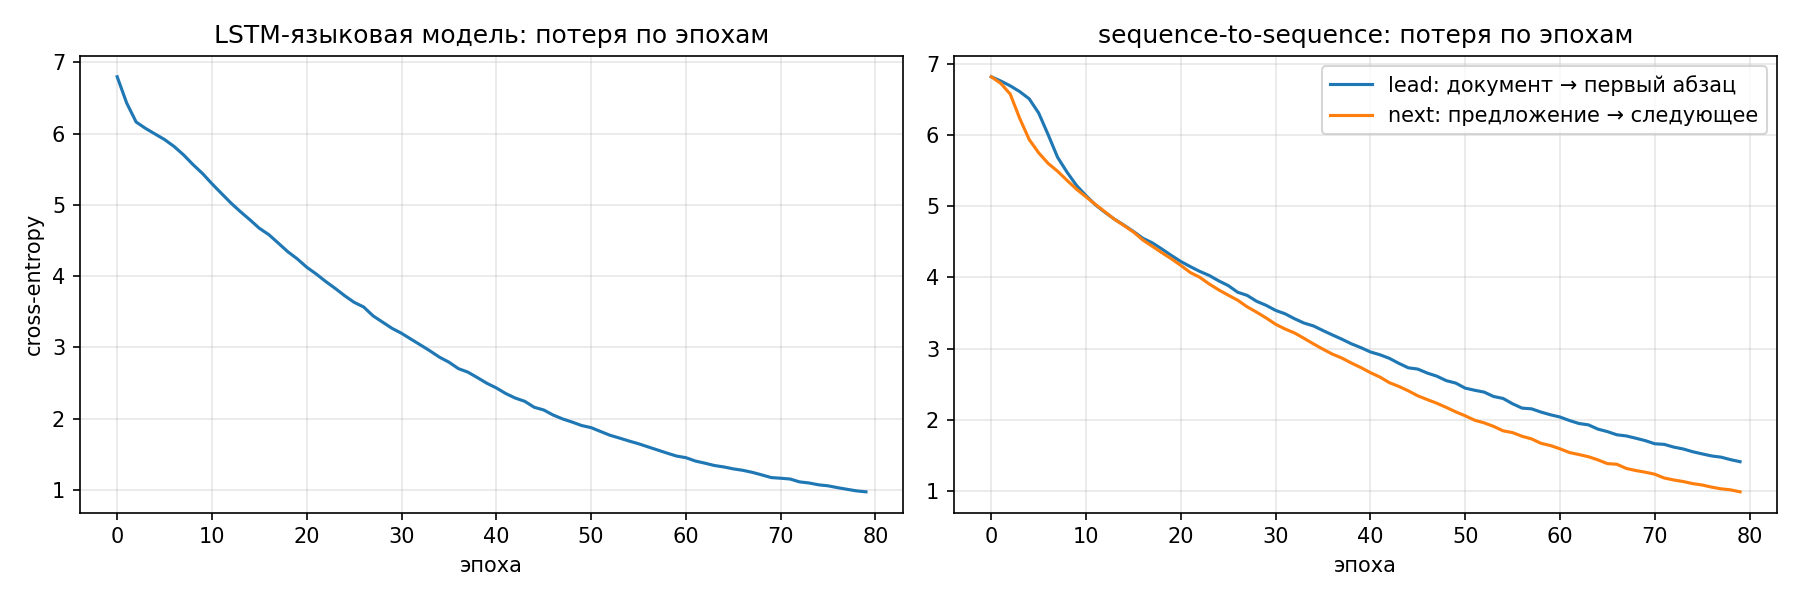

In [19]:

display(Image(filename=str(plot_path)))



## 13. Выводы

1. **LSTM-языковая модель** с эмбеддингом темы и обучением на предложениях
   выучивает стиль корпуса: на демо-корпусе `lm_loss ≈ 0.86`,
   `perplexity ≈ 2.36`, token accuracy ≈ 0.90 (обучающие метрики).
2. **sequence-to-sequence** с вниманием решает две задачи: реферирование
   (`lead`) и продолжение (`next`). На пользовательском корпусе рефераты почти
   дословно совпадают с первым предложением; на RuReviews модель обобщает.
3. **n-граммные ограничения** — ключевой приём на малом корпусе: без них LSTM
   генерирует несвязные цепочки, с ними — локально корректные фразы
   («Процессор и экран с высокой яркостью», «Морковь и лук обжаривают…»).
4. **Шаблонный генератор** даёт гарантированно связный, но extractive текст; он
   разрешён условием и служит baseline и «страховкой» гибрида.
5. **Гибридное ранжирование** объяснимо: у каждого кандидата видны шесть
   признаков, поэтому видно, почему выбран шаблон, seq2seq или LSTM.
6. **Четыре анализатора** решают разные задачи: Байес — тональность, LSA —
   линейные темы, Doc2Vec — shallow-эмбеддинги, CNN/GRU — обучаемое
   нейросетевое представление с супервизией. Генератор надстроен над `lab_4`,
   а остальные три используются для сравнения.
7. Ограничение работы — малый демо-корпус (42 документа): свободная генерация
   LSTM/seq2seq ограничена, поэтому гибрид на демо чаще выбирает шаблон или
   seq2seq. На пользовательском корпусе и RuReviews качество генерации заметно
   выше.
